# 第6章：特征重要性——原MDI/MDA与标准参考

## 统一实验约定
各章节在项目根目录独立运行，无需安装本项目。公共数据处理与实验辅助见 [notebook_common.py](notebook_common.py)，依赖集中在 [requirement.txt](requirement.txt)。

所有章节读取 `data/hs_funds_prices.parquet`，固定种子42。最近1,260个价格观测中，前1,008个用于训练，后252个用于测试。
`SelectComplete` 排除训练收益中的全部缺失；`DropZeroVariance` 的阈值换算后保持原口径：样本方差（`ddof=1`）大于 `1e-12`。默认使用全部合格基金，测试期不重新筛选资产。
先计算单日收益，再排除共同无效日期，不做填充。测试结果**不是连续、可交易的回测**；价格复权口径尚未确认。

初始化只展示数据摘要；完整资产和排除日期可按需查看 `data.assets`、`data.excluded_test_dates`。`ML4AM_SMOKE=1` 仅供自动化小样本验证，正常运行不设置。

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from time import perf_counter
from notebook_common import load_data, setup_notebook, timed

SEED = 42
RUN_EXPENSIVE = False
setup_notebook(SEED)
data = load_data()
X_train, X_test, assets = data.X_train, data.X_test, data.assets
display(data.summary())

数据模式                          全部合格基金
训练期合格基金数                         488
本次使用基金数                          488
训练收益行数                          1007
训练收益区间       2021-07-14 至 2025-09-04
测试候选区间       2025-09-05 至 2026-09-18
测试候选日期数                          252
测试共同有效日期数                        124
排除测试日期数                          128
测试日期覆盖率                       49.21%
Name: 数据概览, dtype: object

## 1. 数据与模型
[原实现](Machine_Learning_for_Asset_Managers/ch6_feature_importance_analysis.py)没有skfolio直接对应接口。
每只基金当日收益为一个特征，目标是固定基金集合下一交易日等权平均收益的方向。
训练末日没有训练期内的下一日标签，因此删除。所有拟合、聚类、排列重要性仅用训练期。
使用100棵树，单次分裂 `max_features=1`，前向三折且隔离1个观测，避免标签跨验证边界。
这与原脚本的普通KFold不同，是明确的时序实验调整。

开始：100棵树：全训练集


完成：100棵树：全训练集，耗时 0.41 秒


,原MDI（零视为缺失）,标准树重要性平均（包含零）
512980.SH,0.002800,0.002529
515120.SH,0.002788,0.002859
501083.SH,0.002750,0.002954
159949.SZ,0.002729,0.002398
159881.SZ,0.002677,0.003659
159898.SZ,0.002657,0.002660
160221.SZ,0.002625,0.002307
510030.SH,0.002561,0.002439
515850.SH,0.002554,0.002307
159899.SZ,0.002552,0.002617


两种MDI的Spearman排名相关： 0.6609355048623148


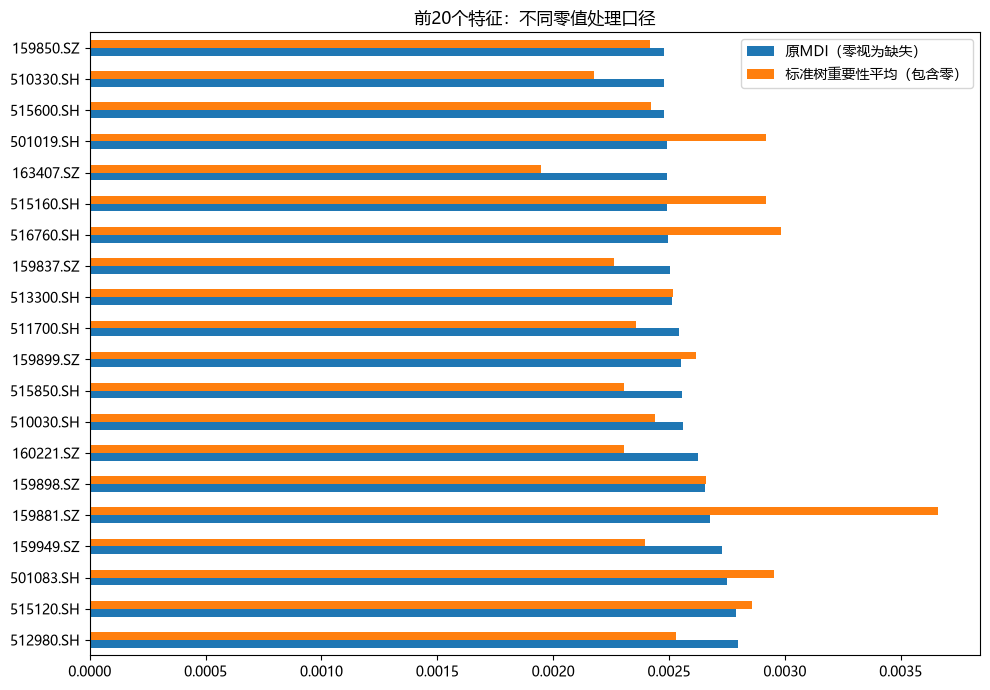

In [2]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import log_loss
from sklearn.inspection import permutation_importance
from sklearn.base import clone
from skfolio.distance import PearsonDistance
from skfolio.cluster import HierarchicalClustering
from Machine_Learning_for_Asset_Managers import ch6_feature_importance_analysis as original
future_return = X_train.mean(axis=1).shift(-1)
X = X_train.loc[future_return.notna()].copy()
y = future_return.loc[X.index].gt(0).astype(int)
assert X.index[-1] < X_train.index[-1] and y.nunique() == 2
classifier = BaggingClassifier(estimator=DecisionTreeClassifier(
    criterion='entropy', max_features=1, class_weight='balanced', random_state=SEED),
    n_estimators=100, max_features=1.0, max_samples=1.0, random_state=SEED, n_jobs=1)
fit, _ = timed('100棵树：全训练集', lambda: clone(classifier).fit(X, y))
mdi_original = original.featImpMDI(fit, X.columns)
reference = np.zeros(X.shape[1])
for tree, features in zip(fit.estimators_, fit.estimators_features_):
    np.add.at(reference, features, tree.feature_importances_ / len(fit.estimators_))
mdi_comparison = pd.DataFrame({'原MDI（零视为缺失）': mdi_original['mean'],
                                '标准树重要性平均（包含零）': reference}, index=X.columns)
display(mdi_comparison.sort_values('原MDI（零视为缺失）', ascending=False).head(20))
print('两种MDI的Spearman排名相关：', mdi_comparison.corr(method='spearman').iloc[0, 1])
mdi_comparison.nlargest(20, '原MDI（零视为缺失）').plot.barh(figsize=(10, 7), title='前20个特征：不同零值处理口径')
plt.tight_layout(); plt.show()

## 2. MDA兼容复现与标准排列重要性
不修改原函数中的只读`.values`洗牌。局部复现改为复制数组、赋回列；保留
`(置乱损失-基准损失)/置乱损失`的原归一化公式，使用三折前向验证。
`permutation_importance`给出未归一化的损失增量；二者不能直接比较绝对大小。
每折每特征一次置乱与标准参考各自运行，随机排列序列不同，结果不要求严格相等。

前向折1/3：原口径排列 100/488


前向折1/3：原口径排列 200/488


前向折1/3：原口径排列 300/488


前向折1/3：原口径排列 400/488


完成前向折1/3


...

前向折3/3：原口径排列 300/488


前向折3/3：原口径排列 400/488


完成前向折3/3


,折,训练截止,验证起点,基准log_loss,耗时秒
0,1,2022-07-27 00:00:00+08:00,2022-07-29 00:00:00+08:00,0.699034,34.868626
1,2,2023-08-08 00:00:00+08:00,2023-08-10 00:00:00+08:00,0.678990,35.100438
2,3,2024-08-20 00:00:00+08:00,2024-08-22 00:00:00+08:00,0.720018,34.582385


,原归一化MDA,跨折标准误（仅描述）,局部复现损失增量,sklearn损失增量
512990.SH,0.001746,0.000462,0.001231,0.000564
502000.SH,0.001491,0.000761,0.001049,0.000856
159848.SZ,0.001455,0.000690,0.001020,0.000802
160221.SZ,0.001428,0.001138,0.001024,0.001157
515810.SH,0.001407,0.000810,0.000981,0.000346
516150.SH,0.001281,0.000626,0.000883,0.000246
516820.SH,0.001276,0.000522,0.000900,0.000278
510180.SH,0.001213,0.000220,0.000846,0.000027
512550.SH,0.001212,0.000850,0.000831,0.000053
159930.SZ,0.001189,0.000445,0.000823,0.000258


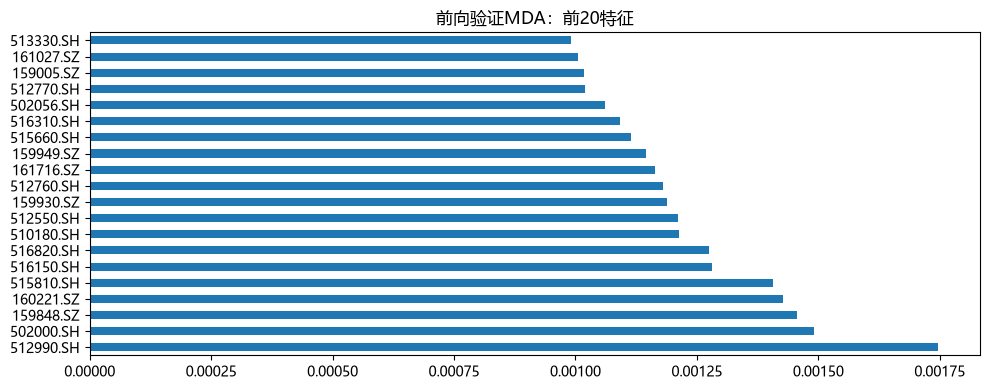

In [3]:
splitter = TimeSeriesSplit(n_splits=3, gap=1)
normalized_scores, raw_scores, standard_scores, fold_rows = [], [], [], []
for fold, (train, test) in enumerate(splitter.split(X), 1):
    start = perf_counter()
    model = clone(classifier).fit(X.iloc[train], y.iloc[train])
    valid, target = X.iloc[test], y.iloc[test]
    baseline = log_loss(target, model.predict_proba(valid), labels=model.classes_)
    rng = np.random.default_rng(SEED+fold)
    normalized, raw_scores_fold = [], []
    for j, column in enumerate(X.columns):
        shuffled = valid.copy()
        shuffled[column] = rng.permutation(valid[column].to_numpy(copy=True))
        loss = log_loss(target, model.predict_proba(shuffled), labels=model.classes_)
        raw_scores_fold.append(loss-baseline)
        normalized.append((loss-baseline)/loss if loss > 0 else np.nan)
        if (j+1) % 100 == 0:
            print(f'前向折{fold}/3：原口径排列 {j+1}/{X.shape[1]}', flush=True)
    standard = permutation_importance(model, valid, target, scoring='neg_log_loss',
                                     n_repeats=1, random_state=SEED+fold, n_jobs=1)
    normalized_scores.append(normalized); raw_scores.append(raw_scores_fold)
    standard_scores.append(standard.importances_mean)
    fold_rows.append({'折': fold, '训练截止': X.index[train[-1]], '验证起点': X.index[test[0]],
                      '基准log_loss': baseline, '耗时秒': perf_counter()-start})
    print(f'完成前向折{fold}/3', flush=True)
normalized_scores = pd.DataFrame(normalized_scores, columns=X.columns)
mda = pd.DataFrame({'原归一化MDA': normalized_scores.mean(),
                    '跨折标准误（仅描述）': normalized_scores.std(ddof=1)/np.sqrt(3),
                    '局部复现损失增量': np.mean(raw_scores, axis=0),
                    'sklearn损失增量': np.mean(standard_scores, axis=0)}, index=X.columns)
display(pd.DataFrame(fold_rows))
display(mda.sort_values('原归一化MDA', ascending=False).head(20))
mda.nlargest(20, '原归一化MDA')['原归一化MDA'].plot.barh(title='前向验证MDA：前20特征')
plt.tight_layout(); plt.show()

## 3. 聚类MDI与可选聚类MDA
本章用训练特征的层次聚类生成固定分组，隔离“重要性统计”与“选择哪种聚类”的问题；
ONC对照见第4章。直接调用原聚类MDI。
可选聚类MDA在每个训练折重新聚类，避免用验证段拟合分组；原口径独立置乱簇内各列，
与共享排列保留簇内关系的分组置乱不同。各折簇标签不对齐，因此逐折报告、不错误地平均簇编号。

In [4]:
cluster_model = HierarchicalClustering().fit(PearsonDistance().fit(X).distance_)
clusters = {int(i): X.columns[cluster_model.labels_ == i].tolist() for i in np.unique(cluster_model.labels_)}
clustered_mdi = original.featImpMDI_Clustered(fit, X.columns, clusters)
display(clustered_mdi.sort_values('mean', ascending=False))
if RUN_EXPENSIVE:
    cluster_rows = []
    for fold, (train, test) in enumerate(splitter.split(X), 1):
        model = clone(classifier).fit(X.iloc[train], y.iloc[train])
        fold_hc = HierarchicalClustering().fit(PearsonDistance().fit(X.iloc[train]).distance_)
        valid, target = X.iloc[test], y.iloc[test]
        base = log_loss(target, model.predict_proba(valid), labels=model.classes_)
        rng = np.random.default_rng(SEED+fold)
        for label in np.unique(fold_hc.labels_):
            members = X.columns[fold_hc.labels_ == label]
            shuffled = valid.copy()
            for member in members:
                shuffled[member] = rng.permutation(valid[member].to_numpy(copy=True))
            loss = log_loss(target, model.predict_proba(shuffled), labels=model.classes_)
            cluster_rows.append({'折': fold, '折内簇': label, '成员': members.tolist(),
                                 '归一化MDA': (loss-base)/loss if loss else np.nan})
    display(pd.DataFrame(cluster_rows))
else:
    print('前向逐折聚类MDA扩展未执行。聚类MDI使用全训练集，只是样本内描述。')

,mean,std
C_4,0.372314,0.003488
C_2,0.340071,0.003785
C_0,0.134016,0.002377
C_1,0.084778,0.002222
C_3,0.06882,0.00185


前向逐折聚类MDA扩展未执行。聚类MDI使用全训练集，只是样本内描述。


## 结论阅读
原MDI的零值处理、MDA的归一化、时间切分和相关特征替代效应均会影响排名。
跨折标准误仅用于描述，金融样本相关性使独立同分布假设不成立。
目标采用固定历史可用基金池，仍有存续偏差与未知价格复权口径，不解释为策略收益证明。